# Predicting Mumbai rent with a neural network
**AI Methods I — Day 4, Track A1 — Group 3 — IAAC MaAI 2026/27**

Ahmed Belahcen, Nandini Rathod, Sanjana Kiran and Akanksha Dhumal.

## 0. What are we trying to predict?
In Day 2, a Random Forest estimated monthly advertised rent from eight property features. This assignment uses the same data and target to ask whether a small neural network does better.

The intended user is a housing researcher comparing early budget scenarios. Underestimating rent can produce an unrealistic budget; overestimating it can make a reasonable option look too expensive. MAE, measured in INR per month, is our main metric. RMSE helps us see the effect of large mistakes, and R² provides another comparison with the earlier model.

For this exercise, a useful result should beat the median baseline and be compared with the Day 2 model. That does not make it accurate enough for real rental decisions. The data is historical, and there is no validated acceptance threshold for practical use.

This notebook and its model files are prepared locally. Publication is pending.

In [1]:
from pathlib import Path
import copy, hashlib, json, random, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, torch
from torch import nn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd().resolve()
if not (ROOT/'notebook/neural_network.ipynb').exists():
    ROOT = ROOT.parent
assert (ROOT/'notebook/neural_network.ipynb').exists(), 'Run from the project root or notebook folder.'
import sys
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from project_io import ensure_data, ensure_model
DATA_DIR, FIG_DIR, MODEL_DIR, REPORT_DIR = [ROOT / p for p in ('data','figures','models','reports')]
for folder in (FIG_DIR, MODEL_DIR, REPORT_DIR): folder.mkdir(exist_ok=True)
TRAIN = True  # False loads the saved neural network; missing files are downloaded when configured.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titlesize':13, 'axes.labelsize':10, 'font.size':10})
COLORS = ['#64748b', '#0f766e', '#7c3aed']
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=170, bbox_inches='tight')
    plt.savefig(MODEL_DIR / name, dpi=170, bbox_inches='tight')
    plt.show()
def metrics(y, p):
    return {'MAE_INR':float(mean_absolute_error(y,p)),
            'RMSE_INR':float(np.sqrt(mean_squared_error(y,p))), 'R2':float(r2_score(y,p))}
print('CPU execution; PyTorch', torch.__version__, '| sklearn', sklearn.__version__)

CPU execution; PyTorch 2.15.0+cpu | sklearn 1.9.1


## 1. Data and train/validation/test sets
Each row is a Mumbai rental advertisement. The cleaned Day 2 file contains 18,846 rows and 26 columns. Its source is Harshal Honde's [Property Rental Listings Dataset](https://www.kaggle.com/datasets/harshalhonde/property-rental-listings-dataset). The group's earlier documentation declares CC BY 4.0; the attribution is retained in `DATA_ATTRIBUTION.md`.

We use the unchanged CSV, not the table enriched with clusters on Day 3. If it is missing, the next cell downloads the pinned Day 2 file and checks its SHA-256. Row order matters because it determines the original test split.

The outer split is the same as Day 2: 80% training and 20% test, with seed 42. We reserve 20% of the training portion for validation. Imputation and scaling use fitting rows only during model selection. This is regression, so no class stratification is needed.

Some repeated advertisements cross the original split. We keep that split for a fair Day 2 comparison, report the overlap, and explain why it limits the results.

Shape: (18846, 26) | fit / validation / test: 12060 3016 3770
Repeated feature+target rows: 2487
Test rows matching outer training on features+target: 752


,Area_num,BHK_num,Bathrooms_num,Balconies_num,Furnished_clean,Facing,Location,Property Type
0,750.0,1.0,1.0,NaN,Furnished,South -West,Mumbai,Apartment
1,1980.0,3.0,4.0,4.0,Unfurnished,East,Mumbai,Apartment
2,1592.0,3.0,3.0,1.0,Unfurnished,North - East,Mumbai,Apartment
3,1305.0,3.0,3.0,3.0,Unfurnished,West,Mumbai,Apartment
4,1350.0,3.0,3.0,NaN,Unfurnished,East,Mumbai,Apartment


,missing,distinct
Area_num,0,1314
BHK_num,0,5
Bathrooms_num,15,6
Balconies_num,10323,5
Furnished_clean,13,3
Facing,0,9
Location,0,1
Property Type,0,6


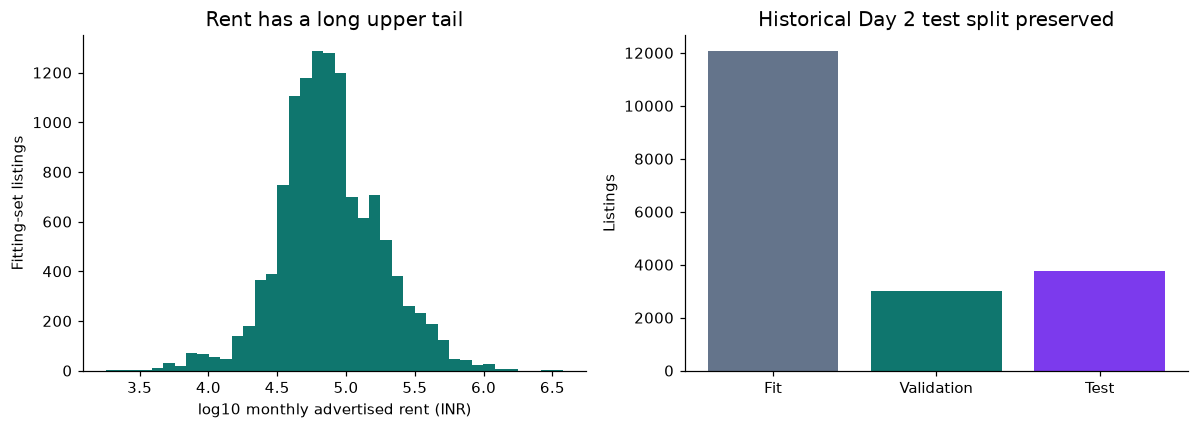

In [2]:
DATA_HASH = '354d28e07432137cdc97a2197a556269137e74135af01186420e2e2917a19ee9'
ensure_data(ROOT)
if not TRAIN: ensure_model(ROOT)
assert hashlib.sha256((DATA_DIR/'mumbai_cleaned.csv').read_bytes()).hexdigest() == DATA_HASH
df = pd.read_csv(DATA_DIR/'mumbai_cleaned.csv')
NUM = ['Area_num','BHK_num','Bathrooms_num','Balconies_num']
CAT = ['Furnished_clean','Facing','Location','Property Type']
FEATURES = NUM + CAT
TARGET = 'Price_num'
model_df = df.dropna(subset=[TARGET]).copy()
assert len(model_df) == 18846 and (model_df[TARGET] > 0).all()
X, y = model_df[FEATURES], model_df[TARGET]
train_ids, test_ids = train_test_split(model_df.index.to_numpy(), test_size=.2, random_state=SEED)
fit_ids, val_ids = train_test_split(train_ids, test_size=.2, random_state=SEED)
assert len(train_ids)==15076 and len(test_ids)==3770
assert not (set(fit_ids)&set(val_ids) or set(train_ids)&set(test_ids))
split_rows = pd.DataFrame({'source_row':model_df.index, 'split':'test'})
split_rows.loc[train_ids,'split']='fit'; split_rows.loc[val_ids,'split']='validation'
split_rows.to_csv(REPORT_DIR/'split_manifest.csv',index=False)
hashes = pd.util.hash_pandas_object(model_df[FEATURES+[TARGET]], index=False)
overlap = hashes.loc[test_ids].isin(set(hashes.loc[train_ids])).to_numpy()
print('Shape:', df.shape, '| fit / validation / test:', len(fit_ids),len(val_ids),len(test_ids))
print('Repeated feature+target rows:', model_df.duplicated(FEATURES+[TARGET]).sum())
print('Test rows matching outer training on features+target:', int(overlap.sum()))
display(X.head())
display(pd.DataFrame({'missing':X.isna().sum(), 'distinct':X.nunique()}))
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(np.log10(y.loc[fit_ids]),bins=40,color=COLORS[1])
axes[0].set(xlabel='log10 monthly advertised rent (INR)',ylabel='Fitting-set listings',title='Rent has a long upper tail')
axes[1].bar(['Fit','Validation','Test'],[len(fit_ids),len(val_ids),len(test_ids)],color=COLORS)
axes[1].set(ylabel='Listings',title='Historical Day 2 test split preserved')
savefig('00_data_and_splits.png')

The rent distribution has a long upper tail. A few very expensive listings can have a large effect on squared error. `Location` contains only the city name, Mumbai, so it cannot tell the model which neighborhood a property belongs to.

## 2. Baselines and input preparation
The main comparator is the final Day 2 Random Forest: 200 trees, maximum depth 10, minimum leaf size 5 and seed 42. The earlier Decision Tree and furnishing classifier were different experiments. A median baseline shows how well we could do without using property features at all.

For the MLP, missing numerical values are replaced with training medians and then standardized. Missing categories use the training mode, followed by one-hot encoding. The forest retains its original preprocessing. Raw rent, price per area, descriptions and Day 3 cluster features are excluded from the inputs.

The network predicts rent divided by 100,000 to make optimization easier. This is a fixed unit conversion, not a statistic learned from the test set. Predictions are converted back to INR and clipped at zero.

In [3]:
def make_preprocessor(scale=True):
    numeric = [('imputer',SimpleImputer(strategy='median'))]
    if scale: numeric.append(('scaler',StandardScaler()))
    return ColumnTransformer([
        ('num',Pipeline(numeric),NUM),
        ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                        ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),CAT)
    ], sparse_threshold=0)
pre_fit = make_preprocessor().fit(X.loc[fit_ids]) if TRAIN else joblib.load(MODEL_DIR/'scaler.joblib')
xf = torch.tensor(pre_fit.transform(X.loc[fit_ids]),dtype=torch.float32)
xv = torch.tensor(pre_fit.transform(X.loc[val_ids]),dtype=torch.float32)
TARGET_SCALE = 100000.0
yf = torch.tensor(y.loc[fit_ids].to_numpy()/TARGET_SCALE,dtype=torch.float32).reshape(-1,1)
yv = torch.tensor(y.loc[val_ids].to_numpy()/TARGET_SCALE,dtype=torch.float32).reshape(-1,1)
def make_forest():
    return Pipeline([('preprocess',make_preprocessor(False)),
                     ('model',RandomForestRegressor(n_estimators=200,max_depth=10,min_samples_leaf=5,
                                                   random_state=SEED,n_jobs=2))])
if TRAIN:
    val_forest = make_forest().fit(X.loc[fit_ids],y.loc[fit_ids])
    val_dummy = DummyRegressor(strategy='median').fit(X.loc[fit_ids],y.loc[fit_ids])
    baseline_validation = {name:metrics(y.loc[val_ids],m.predict(X.loc[val_ids]))
                           for name,m in [('Median',val_dummy),('Day 2 forest',val_forest)]}
    (REPORT_DIR/'baseline_validation.json').write_text(json.dumps(baseline_validation,indent=2))
else: baseline_validation=json.loads((REPORT_DIR/'baseline_validation.json').read_text())
display(pd.DataFrame(baseline_validation).T.round(3))

,MAE_INR,RMSE_INR,R2
Median,66303.802,130490.401,-0.106
Day 2 forest,37767.751,72008.477,0.663


## 3. The neural network
The model has two hidden layers, with 64 and 32 units, and one output for rent. ReLU introduces nonlinearity. Adam updates the weights using batches of 256 and a learning rate of 0.001. The loss is mean squared error on the scaled target.

## 4. Looking inside the model
The next cell shows the layer shapes, parameter counts, weights and intermediate outputs for one example. `parameter_table`, `draw_network` and `layer_outputs` are local inspection helpers. `summary` uses torchinfo when installed and clearly labels its fallback otherwise.

The network diagram displays only the first eight units per layer so it remains readable. Changes in connection weights show that training has changed the network; they do not establish causal importance or prove that a neuron represents a particular housing concept.

In [4]:
def build_model(input_dim, dropout=0.0):
    return nn.Sequential(nn.Linear(input_dim,64),nn.ReLU(),nn.Dropout(dropout),
                         nn.Linear(64,32),nn.ReLU(),nn.Dropout(dropout),nn.Linear(32,1))
def parameter_table(model):
    return pd.DataFrame([{'parameter':name,'shape':str(tuple(p.shape)),'count':p.numel(),
                         'mean':float(p.detach().mean()),'std':float(p.detach().std(unbiased=False))}
                        for name,p in model.named_parameters()])
def layer_outputs(model, sample):
    rows=[]; z=sample.clone(); model.eval()
    with torch.no_grad():
        for i,layer in enumerate(model):
            z=layer(z)
            rows.append({'layer':f'{i}: {type(layer).__name__}', 'shape':str(tuple(z.shape)),
                         'min':float(z.min()),'max':float(z.max()),'mean':float(z.mean()),
                         'first_values':np.round(z[0].numpy()[:6],4).tolist()})
    return pd.DataFrame(rows)
def summary(model,input_size):
    try:
        from torchinfo import summary as torchinfo_summary
        return torchinfo_summary(model,input_size=input_size,verbose=0)
    except ImportError:
        table=layer_outputs(model,torch.zeros(input_size))
        print('torchinfo unavailable: local layer-shape summary; total parameters:',
              sum(p.numel() for p in model.parameters()))
        return table[['layer','shape']]
def draw_network(before,after):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    for ax,model,title in zip(axes,[before,after],['Initial weights','Trained weights']):
        linear=[m for m in model if isinstance(m,nn.Linear)]
        sizes=[linear[0].in_features]+[m.out_features for m in linear]
        shown=[min(8,s) for s in sizes]
        bound=max(float(m.weight.detach().abs().max()) for m in linear)
        for j,m in enumerate(linear):
            w=m.weight.detach().numpy()
            for a in range(shown[j]):
                for b in range(shown[j+1]):
                    ax.plot([j,j+1],[a/max(shown[j]-1,1),b/max(shown[j+1]-1,1)],
                            c='#7c3aed' if w[b,a]>=0 else '#ea580c',alpha=.35,
                            lw=.2+1.8*abs(w[b,a])/max(bound,1e-8))
        for j,s in enumerate(shown):
            ax.scatter([j]*s,np.linspace(0,1,s) if s>1 else [0],s=45,c='#0f172a',zorder=4)
            ax.text(j,-.15,f'{sizes[j]} units',ha='center')
        ax.set_title(title); ax.axis('off')
    fig.suptitle('First up to 8 units per layer; purple + / orange -; width scaled within each panel',fontsize=10)
    savefig('02_network_before_after.png')

torch.manual_seed(SEED)
initial_model=build_model(xf.shape[1])
display(summary(initial_model,(1,xf.shape[1])))
display(parameter_table(initial_model))

torchinfo unavailable: local layer-shape summary; total parameters: 3585


,layer,shape
0,0: Linear,"(1, 64)"
1,1: ReLU,"(1, 64)"
2,2: Dropout,"(1, 64)"
3,3: Linear,"(1, 32)"
4,4: ReLU,"(1, 32)"
5,5: Dropout,"(1, 32)"
6,6: Linear,"(1, 1)"


,parameter,shape,count,mean,std
0,0.weight,"(64, 22)",1408,-0.003587,0.123886
1,0.bias,"(64,)",64,-0.005156,0.116176
2,3.weight,"(32, 64)",2048,-0.000357,0.070819
3,3.bias,"(32,)",32,-0.006757,0.073000
4,6.weight,"(1, 32)",32,-0.009989,0.120246
5,6.bias,"(1,)",1,-0.131235,0.000000


In [5]:
def train_candidate(dropout):
    torch.manual_seed(SEED)
    model=build_model(xf.shape[1],dropout)
    optimizer=torch.optim.Adam(model.parameters(),lr=.001)
    generator=torch.Generator().manual_seed(SEED)
    best_mae=float('inf'); best_epoch=0; best_state=None; history=[]
    for epoch in range(1,251):
        model.train()
        order=torch.randperm(len(xf),generator=generator)
        for batch in order.split(256):
            optimizer.zero_grad()
            loss=nn.functional.mse_loss(model(xf[batch]),yf[batch])
            loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            pf,pv=model(xf),model(xv)
            history.append({'epoch':epoch,'train_loss':float(nn.functional.mse_loss(pf,yf)),
                            'val_loss':float(nn.functional.mse_loss(pv,yv)),
                            'train_MAE':float((pf.clamp(min=0)-yf).abs().mean())*TARGET_SCALE,
                            'val_MAE':float((pv.clamp(min=0)-yv).abs().mean())*TARGET_SCALE})
        score=history[-1]['val_MAE']
        if score<best_mae:
            best_mae=score;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict())
        if epoch-best_epoch>=25: break
    model.load_state_dict(best_state)
    return model,pd.DataFrame(history),best_epoch,best_mae

if TRAIN:
    started=time.perf_counter(); candidates={}; experiment_rows=[]
    for dropout in [0.0,0.2]:
        m,h,epoch,mae=train_candidate(dropout)
        candidates[dropout]=(m,h)
        h.to_csv(REPORT_DIR/f'history_dropout_{dropout:.1f}.csv',index=False)
        torch.save(m.state_dict(),MODEL_DIR/f'validation_dropout_{dropout:.1f}.pt')
        experiment_rows.append({'dropout':dropout,'best_epoch':epoch,'epochs_run':len(h),'validation_MAE_INR':mae})
        print(f'Dropout {dropout}: best epoch {epoch}, validation MAE {mae:,.2f} INR')
    experiment=pd.DataFrame(experiment_rows)
    experiment.to_csv(REPORT_DIR/'validation_experiment.csv',index=False)
    winner=experiment.sort_values('validation_MAE_INR').iloc[0]
    selected_dropout=float(winner.dropout); selected_epochs=int(winner.best_epoch)
    tuned_model,selected_history=candidates[selected_dropout]
    config={'dropout':selected_dropout,'epochs':selected_epochs,'input_dim':int(xf.shape[1]),
            'hidden':[64,32],'learning_rate':.001,'batch_size':256,'target_scale':TARGET_SCALE,
            'seed':SEED,'tuning_seconds':time.perf_counter()-started,'selection_metric':'validation MAE'}
    (MODEL_DIR/'config.json').write_text(json.dumps(config,indent=2))
else:
    config=json.loads((MODEL_DIR/'config.json').read_text());selected_dropout=config['dropout'];selected_epochs=config['epochs']
    experiment=pd.read_csv(REPORT_DIR/'validation_experiment.csv')
    selected_history=pd.read_csv(REPORT_DIR/f'history_dropout_{selected_dropout:.1f}.csv')
    tuned_model=build_model(xf.shape[1],selected_dropout)
    tuned_model.load_state_dict(torch.load(MODEL_DIR/'model.pt',map_location='cpu',weights_only=True))
display(experiment.round(3))

Dropout 0.0: best epoch 28, validation MAE 37,610.84 INR
Dropout 0.2: best epoch 28, validation MAE 37,660.20 INR


,dropout,best_epoch,epochs_run,validation_MAE_INR
0,0.0,28,53,37610.844
1,0.2,28,53,37660.196


## 5. Does dropout help?
We compare dropout 0 and 0.2. The other settings stay the same: layer widths, initial seed, split, optimizer, learning rate and batch size. Each run can continue for up to 250 epochs, with early stopping after 25 epochs without a better validation MAE.

Validation chooses the configuration and epoch. A fresh model is then trained on all 15,076 outer-training rows for that fixed number of epochs. This gives it the same training rows as the Random Forest. The curves below describe the model-selection runs, not the final refit.

With `TRAIN=False`, the notebook reads those recorded histories and inspects the saved final model. It does not need the intermediate neural-network checkpoints.

Inspecting the validation-selected network.


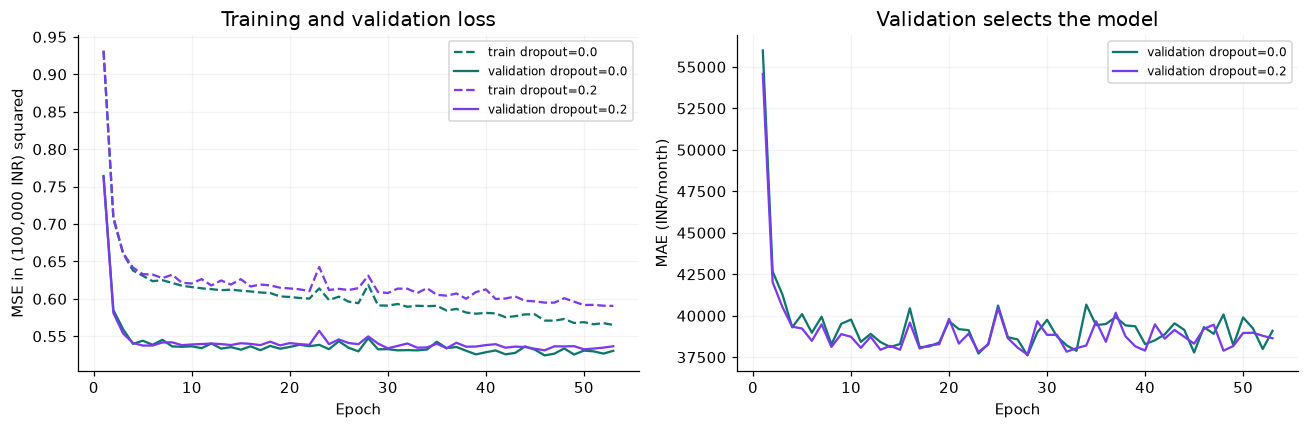

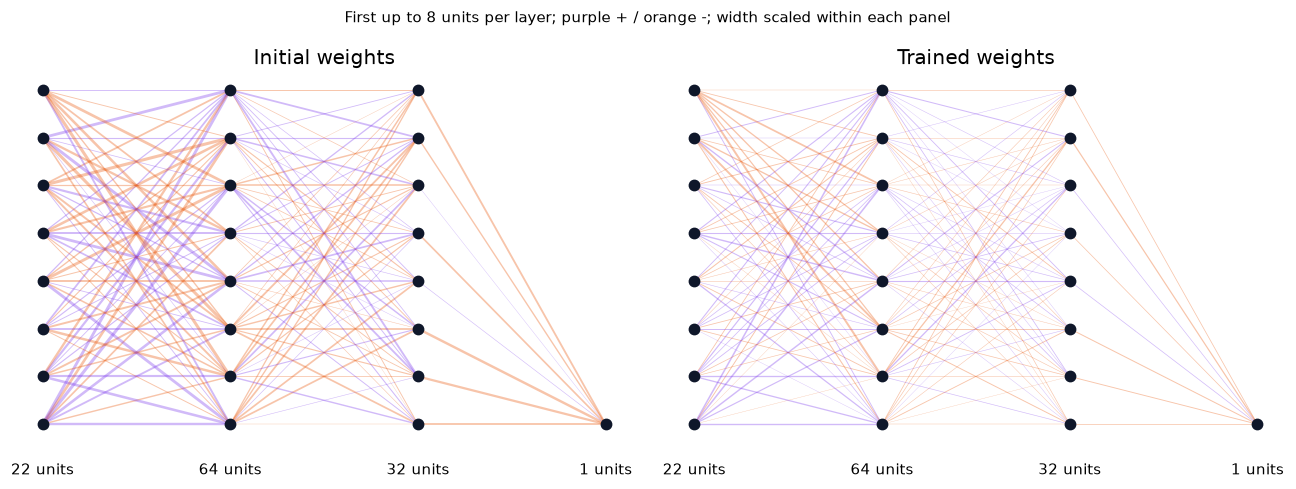

,parameter,shape,count,mean,std
0,0.weight,"(64, 22)",1408,0.009480,0.153041
1,0.bias,"(64,)",64,0.005073,0.119055
2,3.weight,"(32, 64)",2048,0.002364,0.096858
3,3.bias,"(32,)",32,-0.000425,0.069218
4,6.weight,"(1, 32)",32,0.025485,0.150507
5,6.bias,"(1,)",1,-0.093038,0.000000


,layer,shape,min,max,mean,first_values
0,0: Linear,"(1, 64)",-0.758193,0.727019,0.050469,"[0.5806999802589417, -0.06719999760389328, -0...."
1,1: ReLU,"(1, 64)",0.000000,0.727019,0.176369,"[0.5806999802589417, 0.0, 0.0, 0.0621999986469..."
2,2: Dropout,"(1, 64)",0.000000,0.727019,0.176369,"[0.5806999802589417, 0.0, 0.0, 0.0621999986469..."
3,3: Linear,"(1, 32)",-0.431303,0.689614,0.036872,"[-0.30390000343322754, -0.1088000014424324, -0..."
4,4: ReLU,"(1, 32)",0.000000,0.689614,0.187523,"[0.0, 0.0, 0.0, 0.40369999408721924, 0.0, 0.28..."
5,5: Dropout,"(1, 32)",0.000000,0.689614,0.187523,"[0.0, 0.0, 0.0, 0.40369999408721924, 0.0, 0.28..."
6,6: Linear,"(1, 1)",0.962776,0.962776,0.962776,[0.9628000259399414]


Selected dropout=0.0, epoch=28; training MAE=36,307, validation MAE=37,611 INR.
Final recorded validation MAE=39,091 INR. Compare with the best epoch to judge late deterioration.
Weights and activations show a numerical transformation, not a causal explanation or named architectural concepts.


In [6]:
print('Inspecting the validation-selected network.' if TRAIN else 'Inspecting the saved final network; curves show the recorded validation experiment.')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for d,c in zip([0.0,0.2],['#0f766e','#7c3aed']):
    h=pd.read_csv(REPORT_DIR/f'history_dropout_{d:.1f}.csv')
    axes[0].plot(h.epoch,h.train_loss,color=c,ls='--',label=f'train dropout={d}')
    axes[0].plot(h.epoch,h.val_loss,color=c,label=f'validation dropout={d}')
    axes[1].plot(h.epoch,h.val_MAE,color=c,label=f'validation dropout={d}')
axes[0].set(xlabel='Epoch',ylabel='MSE in (100,000 INR) squared',title='Training and validation loss')
axes[1].set(xlabel='Epoch',ylabel='MAE (INR/month)',title='Validation selects the model')
for ax in axes: ax.legend(fontsize=8);ax.grid(alpha=.15)
savefig('01_training_curves.png')
draw_network(initial_model,tuned_model)
display(parameter_table(tuned_model))
display(layer_outputs(tuned_model,xv[:1]))
parameter_table(tuned_model).to_csv(REPORT_DIR/'parameter_table.csv',index=False)
layer_outputs(tuned_model,xv[:1]).to_csv(REPORT_DIR/'layer_outputs.csv',index=False)
best_row=selected_history.loc[selected_history.val_MAE.idxmin()]
print(f'Selected dropout={selected_dropout}, epoch={selected_epochs}; training MAE={best_row.train_MAE:,.0f}, validation MAE={best_row.val_MAE:,.0f} INR.')
print(f'Final recorded validation MAE={selected_history.val_MAE.iloc[-1]:,.0f} INR. Compare with the best epoch to judge late deterioration.')
print('Weights and activations show a numerical transformation, not a causal explanation or named architectural concepts.')

In [7]:
if TRAIN:
    final_started=time.perf_counter()
    final_pre=make_preprocessor().fit(X.loc[train_ids])
    xt=torch.tensor(final_pre.transform(X.loc[train_ids]),dtype=torch.float32)
    yt=torch.tensor(y.loc[train_ids].to_numpy()/TARGET_SCALE,dtype=torch.float32).reshape(-1,1)
    config['input_dim']=int(xt.shape[1])
    torch.manual_seed(SEED)
    final_model=build_model(xt.shape[1],selected_dropout)
    optimizer=torch.optim.Adam(final_model.parameters(),lr=.001)
    generator=torch.Generator().manual_seed(SEED)
    for epoch in range(selected_epochs):
        final_model.train()
        for batch in torch.randperm(len(xt),generator=generator).split(256):
            optimizer.zero_grad()
            loss=nn.functional.mse_loss(final_model(xt[batch]),yt[batch])
            loss.backward();optimizer.step()
    final_model.eval()
    forest=make_forest().fit(X.loc[train_ids],y.loc[train_ids])
    dummy=DummyRegressor(strategy='median').fit(X.loc[train_ids],y.loc[train_ids])
    torch.save(final_model.state_dict(),MODEL_DIR/'model.pt')
    joblib.dump(final_pre,MODEL_DIR/'scaler.joblib')  # complete preprocessing, not just numeric scaler
    joblib.dump(forest,MODEL_DIR/'day2_random_forest.joblib')
    joblib.dump(dummy,MODEL_DIR/'median_baseline.joblib')
    config['refit_seconds']=time.perf_counter()-final_started
    config['parameters']=sum(p.numel() for p in final_model.parameters())
    config['features']=FEATURES;config['encoded_features']=final_pre.get_feature_names_out().tolist()
    (MODEL_DIR/'config.json').write_text(json.dumps(config,indent=2))
else:
    final_pre=joblib.load(MODEL_DIR/'scaler.joblib')
    final_model=build_model(config['input_dim'],config['dropout'])
    final_model.load_state_dict(torch.load(MODEL_DIR/'model.pt',map_location='cpu',weights_only=True))
    final_model.eval()
    forest=make_forest().fit(X.loc[train_ids],y.loc[train_ids])  # reproduce the Day 2 comparator
    dummy=DummyRegressor(strategy='median').fit(X.loc[train_ids],y.loc[train_ids])
def predict_mlp(frame,model=final_model,pre=final_pre):
    model.eval()
    with torch.no_grad():
        return np.maximum(model(torch.tensor(pre.transform(frame[FEATURES]),dtype=torch.float32)).numpy().ravel()*TARGET_SCALE,0)
print('Selection frozen before test scoring:',config)

Selection frozen before test scoring: {'dropout': 0.0, 'epochs': 28, 'input_dim': 23, 'hidden': [64, 32], 'learning_rate': 0.001, 'batch_size': 256, 'target_scale': 100000.0, 'seed': 42, 'tuning_seconds': 9.157375500013586, 'selection_metric': 'validation MAE', 'refit_seconds': 3.47296650003409, 'parameters': 3649, 'features': ['Area_num', 'BHK_num', 'Bathrooms_num', 'Balconies_num', 'Furnished_clean', 'Facing', 'Location', 'Property Type'], 'encoded_features': ['num__Area_num', 'num__BHK_num', 'num__Bathrooms_num', 'num__Balconies_num', 'cat__Furnished_clean_Furnished', 'cat__Furnished_clean_Semi-Furnished', 'cat__Furnished_clean_Unfurnished', 'cat__Facing_East', 'cat__Facing_North', 'cat__Facing_North - East', 'cat__Facing_North - West', 'cat__Facing_South', 'cat__Facing_South - East', 'cat__Facing_South -West', 'cat__Facing_Unknown', 'cat__Facing_West', 'cat__Location_Mumbai', 'cat__Property Type_Apartment', 'cat__Property Type_Builder Floor Apartment', 'cat__Property Type_Penthouse